In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
df = pd.read_csv("../data/raw/TelcoChurnData.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6352-ABCDE,Male,0,Yes,Yes,24,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,No,Electronic check,50.00,1200.00,No
1,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
2,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
4,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No


In [32]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors = "coerce")

In [33]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [34]:
df.drop(columns=["customerID"], inplace=True)


In [35]:
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [37]:
categorical_cols = X.select_dtypes(include="object").columns
numerical_cols = X.select_dtypes(exclude="object").columns

In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)
    ]
)

In [39]:
from sklearn.tree import DecisionTreeClassifier
dt_model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=50,
            random_state=42
        ))
    ]
)

In [40]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]
print("ROC-AUC: ", roc_auc_score(y_test, y_prob_dt))
print(classification_report(y_test, y_pred_dt))

ROC-AUC:  0.8273063111937792
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [41]:
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=50,
            random_state=42,
            n_jobs=1
        ))
    ]
)

In [42]:
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print(classification_report(y_test, y_pred_rf))

ROC-AUC: 0.848577850112377
              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1035
           1       0.67      0.46      0.54       374

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.71      1409
weighted avg       0.78      0.80      0.78      1409



In [43]:
rf_pipeline = rf_model

In [44]:
preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_classifier = rf_pipeline.named_steps["classifier"]

In [45]:
num_features = numerical_cols
cat_features = preprocessor.named_transformers_["cat"] \
    .get_feature_names_out(categorical_cols)
feature_names = list(num_features) + list(cat_features)

In [46]:
importances = rf_classifier.feature_importances_
importances_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

In [47]:
importances_df.head(15)

,feature,importance
1,tenure,0.215359
3,TotalCharges,0.128672
10,InternetService_Fiber optic,0.102465
25,Contract_Two year,0.091044
28,PaymentMethod_Electronic check,0.090282
2,MonthlyCharges,0.073401
13,OnlineSecurity_Yes,0.039674
24,Contract_One year,0.035417
19,TechSupport_Yes,0.027538
22,StreamingMovies_No internet service,0.021584


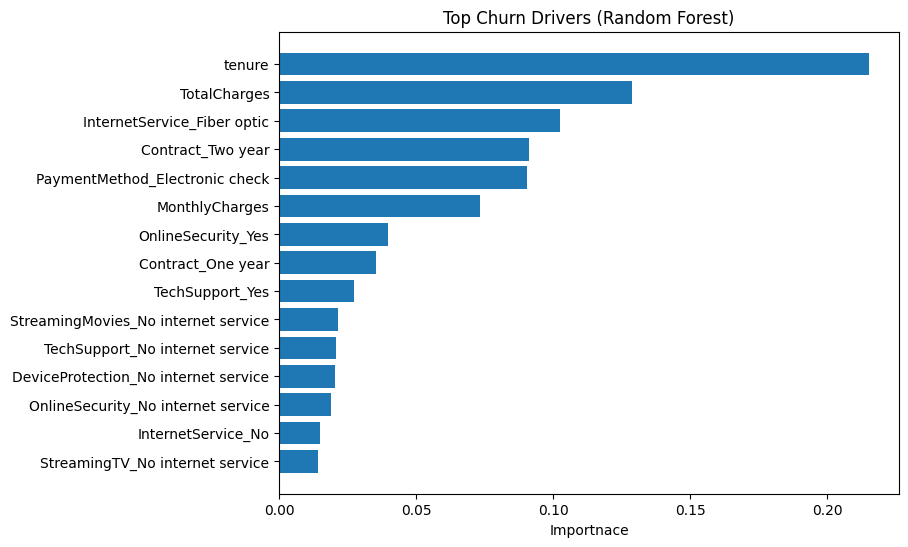

In [48]:
top_n = 15
plt.figure(figsize = (8, 6))
plt.barh(
    importances_df["feature"][:top_n][::-1],
    importances_df["importance"][:top_n][::-1]
)
plt.xlabel("Importnace")
plt.title("Top Churn Drivers (Random Forest)")
plt.show()

In [49]:
y_proba = rf_pipeline.predict_proba(X_test)[:, 1]

In [50]:
from sklearn.metrics import precision_score, recall_score, classification_report, confusion_matrix
thresholds = np.arange(0.2, 0.81, 0.05)
results = []
for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    results.append({
        "threshold": t,
        "precision": precision_score(y_test, y_pred_t),
        "recall": recall_score(y_test, y_pred_t)
    })
threshold_df = pd.DataFrame(results)
threshold_df

c:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,threshold,precision,recall
0,0.20,0.452446,0.890374
1,0.25,0.494488,0.839572
2,0.30,0.546332,0.756684
3,0.35,0.584444,0.703209
4,0.40,0.619792,0.636364
5,0.45,0.661491,0.569519
6,0.50,0.670588,0.457219
7,0.55,0.718750,0.368984
8,0.60,0.740458,0.259358
9,0.65,0.821429,0.184492


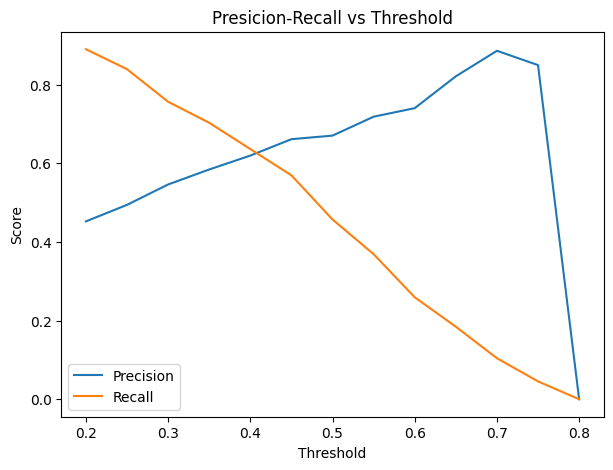

In [51]:
plt.figure(figsize=(7,5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label = "Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label = "Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Presicion-Recall vs Threshold")
plt.legend()
plt.show()

In [52]:
chosen_threshold = 0.35
y_pred_opt = (y_proba >= chosen_threshold).astype(int)
print(confusion_matrix(y_test, y_pred_opt))
print(classification_report(y_test, y_pred_opt))

[[848 187]
 [111 263]]
              precision    recall  f1-score   support

           0       0.88      0.82      0.85      1035
           1       0.58      0.70      0.64       374

    accuracy                           0.79      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.79      0.79      1409



In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify = y, random_state = 42
)
rf_pipeline.fit(X_train, y_train)
train_proba = rf_pipeline.predict_proba(X_train)[:, 1]
test_proba = rf_pipeline.predict_proba(X_test)[:, 1]
print("Train ROC-AUC: ", roc_auc_score(y_train, train_proba))
print("Test ROC-AUC: ", roc_auc_score(y_test, test_proba))

Train ROC-AUC:  0.8594696492333543
Test ROC-AUC:  0.848577850112377


In [54]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = cross_val_score(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)
print("CV ROC-AUC scores:", cv_auc)
print("Mean CV ROC-AUC:", cv_auc.mean())
print("Std CV ROC-AUC:", cv_auc.std())

CV ROC-AUC scores: [0.85676974 0.84699295 0.84930765 0.81520318 0.84904223]
Mean CV ROC-AUC: 0.8434631526069578
Std CV ROC-AUC: 0.014515061637967409


In [55]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score
y_cv_proba = cross_val_predict(
    rf_pipeline,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]
print("PR-AUC:", average_precision_score(y, y_cv_proba))

PR-AUC: 0.6522287454393285


In [56]:
final_model = rf_pipeline
final_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [57]:
import joblib
joblib.dump(final_model, "churn_model.pkl")

['churn_model.pkl']

In [58]:
loaded_model = joblib.load("churn_model.pkl")

In [59]:
THRESHOLD = 0.35
def predict_churn(customer_df, model=loaded_model, threshold=THRESHOLD):
    """
    customer_df: pandas DataFrame with same schema as training data
    returns: probability and churn decision
    """
    proba = model.predict_proba(customer_df)[:, 1]
    decision = (proba >= threshold).astype(int)
    return pd.DataFrame({
        "churn_probability": proba,
        "churn_prediction": decision
    })


In [60]:
sample_customer = X.iloc[[0]]
predict_churn(sample_customer)

,churn_probability,churn_prediction
0,0.132198,0
